# Instalar mi paquete

In [ ]:
%pip install -q "git+https://github.com/adbaldel/Complex-Dynamics-Thesis.git"

In [ ]:
%pip install -q --upgrade "IPython>=9.17" "pyvista>=0.48.4"

# Imports

In [1]:
import complex_dynamics.calculator as dcalc
import complex_dynamics.plot as dplot
import matplotlib.pyplot as plt
import numpy as np
from complex_dynamics.rational_map import RationalMap

# Ejemplo del libro ($z \mapsto z^2 - 1$)

Defino la función $z \mapsto z^2 - 1$ y una función de python precompilada para obtener los tiempos de escape de cada punto en una región del plano según la función $z \mapsto z^2 - 1$.

In [2]:
R2m1 = RationalMap.from_latex("z^2 - 1")
print(R2m1)
R2m1_twice = RationalMap.from_latex("(z^2 - 1)^2 - 1")
print(R2m1_twice)

z^{2} - 1
z^{4} - 2 z^{2}


Calculo los tiempos de escape.

In [3]:
max_distance_to_origin = 2

xmin = -max_distance_to_origin
xmax = max_distance_to_origin
ymin = -max_distance_to_origin
ymax = max_distance_to_origin

xpixels = 1000
ypixels = 1000

mesh = dcalc.create_mesh(
    xmin, xmax, ymin, ymax, xpixels=xpixels, ypixels=ypixels
)

max_iterations = 100

divergence_times = dcalc.calculate_divergence_times(
    mesh,
    R2m1,
    max_iterations=max_iterations,
    escape_radius=(1 + np.sqrt(5)) / 2,
)

Dibujo el conjunto de Julia.

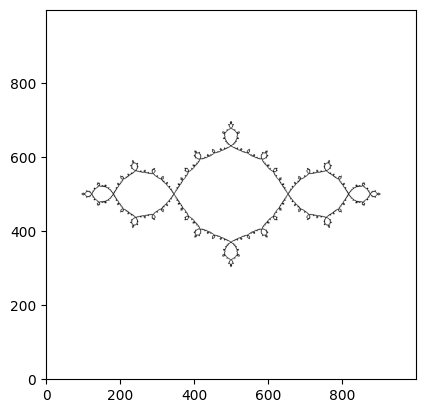

In [4]:
fig, ax = dplot.plot_divergence_times_boundary(
    divergence_times, max_iterations=max_iterations
)

Marco los puntos fijos y el extremo de $F_{-1}$.

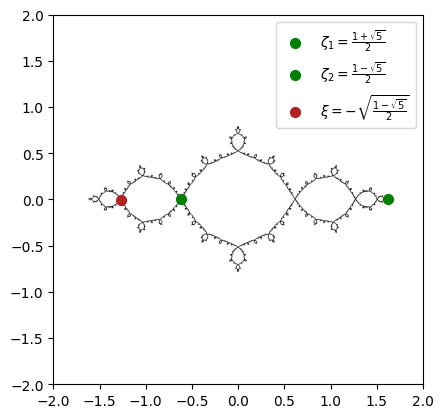

In [5]:
zeta1 = (
    1 + np.sqrt(5)
) / 2 + 1e-2j  # La parte imaginaria es para que quede mejor en la visualización
zeta2 = (1 - np.sqrt(5)) / 2
chi = -np.sqrt(zeta1)

fig, ax = dplot.plot_divergence_times_boundary(
    divergence_times,
    max_iterations=max_iterations,
    extent=[xmin, xmax, ymin, ymax],
)
ax.scatter(
    zeta1.real,
    zeta1.imag,
    label=r"$\zeta_1 = \frac{1 + \sqrt{5}}{2}$",
    marker="o",
    color="green",
    s=50,
)
ax.scatter(
    zeta2.real,
    zeta2.imag,
    label=r"$\zeta_2 = \frac{1 - \sqrt{5}}{2}$",
    marker="o",
    color="green",
    s=50,
)
ax.scatter(
    chi.real,
    chi.imag,
    label=r"$\xi = -\sqrt{\frac{1 - \sqrt{5}}{2}}$",
    marker="o",
    color="firebrick",
    s=50,
)
ax.legend()

Marco los $-1$ y $0$ que forman un 2-ciclo atractor.

Text(10, -4, '$-1$')

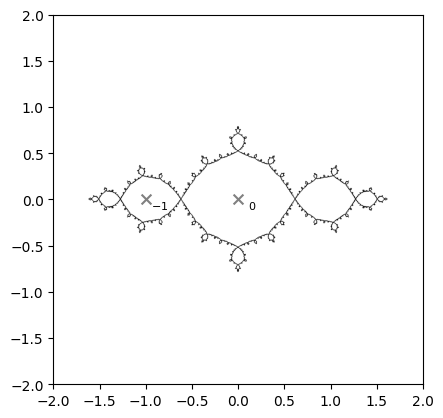

In [6]:
attractor1 = complex(0, 0)
attractor2 = complex(-1, 0)

fig1, ax1 = dplot.plot_divergence_times_boundary(
    divergence_times,
    max_iterations=max_iterations,
    extent=[xmin, xmax, ymin, ymax],
)
ax1.scatter(
    attractor1.real,
    attractor1.imag,
    label=r"$0$",
    marker="x",
    color="gray",
    s=50,
)
ax1.annotate(
    "$0$",
    (attractor1.real, attractor1.imag),
    xytext=(10, -4),
    textcoords="offset points",
    ha="center",
    va="center",
    fontsize=8,
    zorder=2,
)
ax1.scatter(
    attractor2.real,
    attractor2.imag,
    label=r"$-1$",
    marker="x",
    color="gray",
    s=50,
)
ax1.annotate(
    "$-1$",
    (attractor2.real, attractor2.imag),
    xytext=(10, -4),
    textcoords="offset points",
    ha="center",
    va="center",
    fontsize=8,
    zorder=2,
)

Muestro las componentes alternas que acaban en $F_{-1}$ y $F_0$ alternando de una a otra.

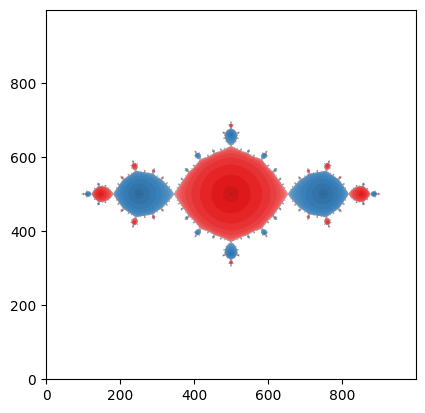

In [7]:
attractors = np.array([attractor1, attractor2], dtype=np.complex128)

convergence_times, convergence_points = dcalc.calculate_convergence_times(
    mesh,
    R2m1_twice,
    attractors,
    max_iterations=max_iterations,
    tolerance=1e-6,
)

fig2, ax2 = dplot.plot_convergence_times(
    convergence_times,
    convergence_points,
    attractors,
    max_iterations=max_iterations,
)

Text(0, -15, '$\\frac{1 - \\sqrt{5}}{2}$')

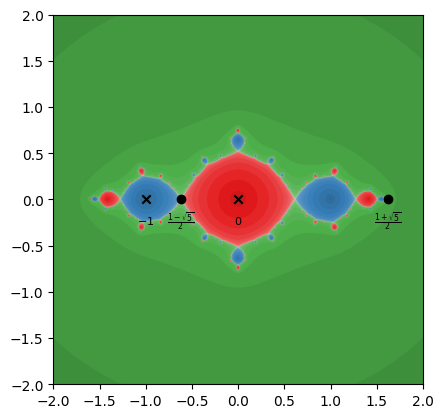

In [8]:
attractors = np.array(
    [attractor1, attractor2, complex(np.inf, 0)], dtype=np.complex128
)

tolerance = 1e-6
infinity_threshold = 1e10

convergence_times, convergence_points = dcalc.calculate_convergence_times(
    mesh,
    R2m1_twice,
    attractors,
    max_iterations=max_iterations,
    tolerance=tolerance,
)

# Plot 1: The solid colored basins
fig3, ax3 = dplot.plot_convergence_times(
    convergence_times,
    convergence_points,
    attractors,
    max_iterations=max_iterations,
    extent=[xmin, xmax, ymin, ymax],
)
ax3.scatter(
    attractors[0].real,
    attractors[0].imag,
    label="$0$",
    color="black",
    marker="x",
    zorder=2,
)
ax3.annotate(
    "$0$",
    (attractors[0].real, attractors[0].imag),
    xytext=(0, -15),
    textcoords="offset points",
    ha="center",
    va="center",
    fontsize=8,
    zorder=2,
)
ax3.scatter(
    attractors[1].real,
    attractors[1].imag,
    label="$-1$",
    color="black",
    marker="x",
    zorder=2,
)
ax3.annotate(
    "$-1$",
    (attractors[1].real, attractors[1].imag),
    xytext=(0, -15),
    textcoords="offset points",
    ha="center",
    va="center",
    fontsize=8,
    zorder=2,
)
ax3.scatter(
    (1 + np.sqrt(5)) / 2,
    0,
    label=r"$\frac{1 + \sqrt{5}}{2}$",
    color="black",
    zorder=2,
)
ax3.annotate(
    r"$\frac{1 + \sqrt{5}}{2}$",
    ((1 + np.sqrt(5)) / 2, 0),
    xytext=(0, -15),
    textcoords="offset points",
    ha="center",
    va="center",
    fontsize=8,
    zorder=2,
)
ax3.scatter(
    (1 - np.sqrt(5)) / 2,
    0,
    label=r"$\frac{1 - \sqrt{5}}{2}$",
    color="black",
    zorder=2,
)
ax3.annotate(
    r"$\frac{1 - \sqrt{5}}{2}$",
    ((1 - np.sqrt(5)) / 2, 0),
    xytext=(0, -15),
    textcoords="offset points",
    ha="center",
    va="center",
    fontsize=8,
    zorder=2,
)